In [ ]:
df <- read.csv('/content/dataCow1.csv')
head(df)

,Порядковый.номер,Порода,Живая.масса,Процент.жирности,Способ.кормления,Годовой.удой.в.кг
,<int>,<chr>,<dbl>,<dbl>,<chr>,<dbl>
1,1,Ярославская,590.04,4.31,Травяной,3823.33
2,2,Ярославская,500.30,4.09,Травяной,1000.00
3,3,Ярославская,538.29,4.03,Травяной,NA
4,4,Ярославская,506.71,4.23,Травяной,3311.06
5,5,Ярославская,479.27,3.70,Травяной,3237.03
6,6,Ярославская,595.81,4.03,Травяной,3900.17


Перед обработкой необходимо путём логических умозаключений выявить данные значительно влияющие на мясо-молочную продуктивность и отбросить оставшиеся, это позволит сэкономить ресурсы при обработке данных.
После отбора, данные очищаются от шума, происходит избавление от аномалий и выбросов, заполнение пустых полей, масштабирование и преобразование переменных.
Данные действия необходимы для получения достоверных результатов анализа.
Также необходимо обратить внимание на пропущенные значения и выбросы.

In [ ]:
summary(df)

 Порядковый.номер    Порода           Живая.масса    Процент.жирности
 Min.   :  1.0    Length:720         Min.   :233.4   Min.   :3.340   
 1st Qu.:180.8    Class :character   1st Qu.:448.9   1st Qu.:3.780   
 Median :360.5    Mode  :character   Median :516.4   Median :3.960   
 Mean   :360.5                       Mean   :520.7   Mean   :4.278   
 3rd Qu.:540.2                       3rd Qu.:592.4   3rd Qu.:4.280   
 Max.   :720.0                       Max.   :805.2   Max.   :7.280   
                                                                     
 Способ.кормления   Годовой.удой.в.кг
 Length:720         Min.   : 1000    
 Class :character   1st Qu.: 3157    
 Mode  :character   Median : 3766    
                    Mean   : 3777    
                    3rd Qu.: 4355    
                    Max.   :10000    
                    NA's   :5        

На изображении выше видно, что в целевой переменной (Годовой удой в кг) находится 5 пустых значений, их необходимо устранить. Для этого будет рассчитана медиана без учёта пропусков, ею пробелы будут заполнены.


In [ ]:
median_yield <- median(df$`Годовой.удой.в.кг`, na.rm=T)
median_yield

[1] 3765.86

In [ ]:
df$`Годовой.удой.в.кг`[is.na(df$`Годовой.удой.в.кг`)] <- median_yield
summary(df)

 Порядковый.номер    Порода           Живая.масса    Процент.жирности
 Min.   :  1.0    Length:720         Min.   :233.4   Min.   :3.340   
 1st Qu.:180.8    Class :character   1st Qu.:448.9   1st Qu.:3.780   
 Median :360.5    Mode  :character   Median :516.4   Median :3.960   
 Mean   :360.5                       Mean   :520.7   Mean   :4.278   
 3rd Qu.:540.2                       3rd Qu.:592.4   3rd Qu.:4.280   
 Max.   :720.0                       Max.   :805.2   Max.   :7.280   
 Способ.кормления   Годовой.удой.в.кг
 Length:720         Min.   : 1000    
 Class :character   1st Qu.: 3161    
 Mode  :character   Median : 3766    
                    Mean   : 3777    
                    3rd Qu.: 4346    
                    Max.   :10000    

Если обратить на наименьшие и наибольшие значения, возникнет подозрение на выбросы в значениях целевой переменной, размах вариации для этой переменной составит 9000 кг. Для определения нахождения выбросов был построен график ящик с усами.

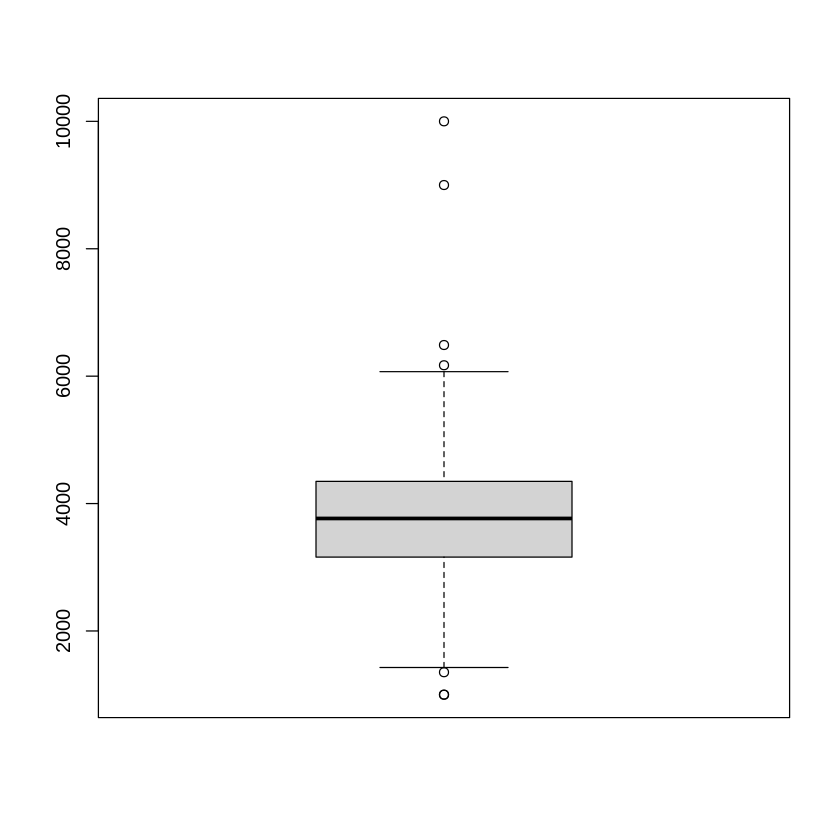

In [ ]:
boxplot(df$`Годовой.удой.в.кг`)

In [ ]:
qr <- IQR(df$`Годовой.удой.в.кг`)
q13 <- quantile(df$`Годовой.удой.в.кг`, probs = c(0.25, 0.75))
qr
q13

[1] 1184.68

25%      75% 
3160.953 4345.632

In [ ]:
for (i in 1:nrow(df)) {
  if ((q13[1] - df$`Годовой.удой.в.кг`[i] > 1.4*qr) | (df$`Годовой.удой.в.кг`[i] - q13[2] > 1.4*qr)) {
    df$`Годовой.удой.в.кг`[i] = NA
  }
}
summary(df)

 Порядковый.номер    Порода           Живая.масса    Процент.жирности
 Min.   :  1.0    Length:720         Min.   :233.4   Min.   :3.340   
 1st Qu.:180.8    Class :character   1st Qu.:448.9   1st Qu.:3.780   
 Median :360.5    Mode  :character   Median :516.4   Median :3.960   
 Mean   :360.5                       Mean   :520.7   Mean   :4.278   
 3rd Qu.:540.2                       3rd Qu.:592.4   3rd Qu.:4.280   
 Max.   :720.0                       Max.   :805.2   Max.   :7.280   
                                                                     
 Способ.кормления   Годовой.удой.в.кг
 Length:720         Min.   :1721     
 Class :character   1st Qu.:3163     
 Mode  :character   Median :3766     
                    Mean   :3761     
                    3rd Qu.:4321     
                    Max.   :5998     
                    NA's   :10       

In [ ]:
df <- na.omit(df)
summary(df)

 Порядковый.номер    Порода           Живая.масса    Процент.жирности
 Min.   :  1.0    Length:710         Min.   :239.5   Min.   :3.340   
 1st Qu.:182.2    Class :character   1st Qu.:448.6   1st Qu.:3.780   
 Median :359.5    Mode  :character   Median :516.4   Median :3.960   
 Mean   :359.7                       Mean   :520.0   Mean   :4.276   
 3rd Qu.:536.8                       3rd Qu.:591.6   3rd Qu.:4.280   
 Max.   :720.0                       Max.   :799.8   Max.   :7.280   
 Способ.кормления   Годовой.удой.в.кг
 Length:710         Min.   :1721     
 Class :character   1st Qu.:3163     
 Mode  :character   Median :3766     
                    Mean   :3761     
                    3rd Qu.:4321     
                    Max.   :5998     

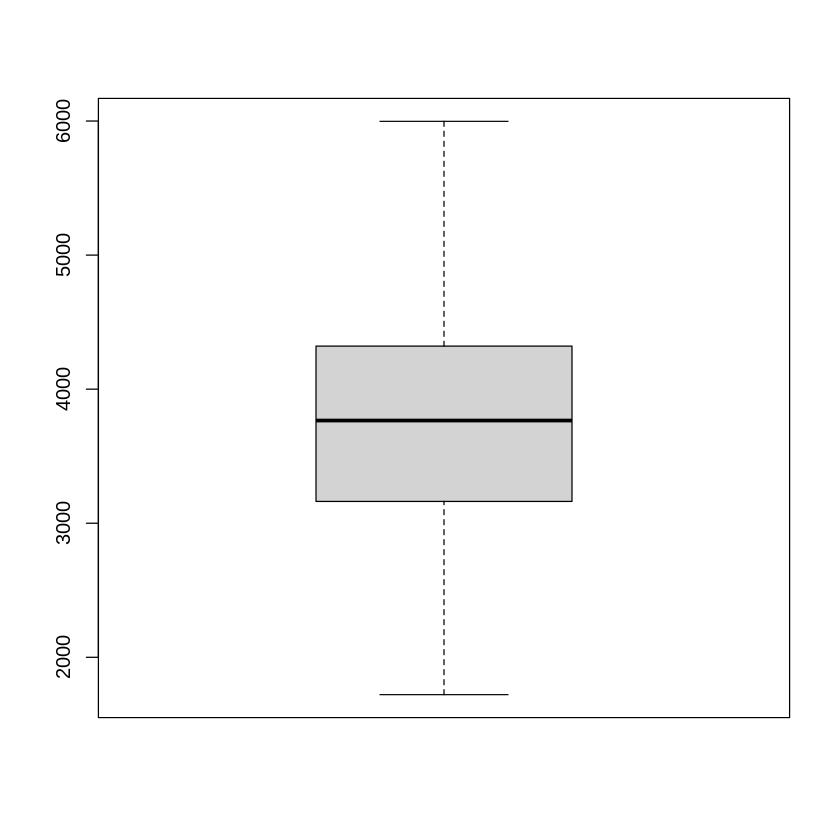

In [ ]:
boxplot(df$`Годовой.удой.в.кг`)

In [ ]:
df_temp <- data.frame(row.names = names(df))
for (i in 1:nrow(df)) {
  if (!is.na(df$`Годовой.удой.в.кг`[i])){
      df_temp = rbind.data.frame(df_temp, df[i])
  }
}
summary(df_temp)

ERROR: Error in match.names(clabs, names(xi)): names do not match previous names
